# Gaussian process regression with noisy targets

Fit six observations from the signal $f(x) = x \sin(x)$, first with noise-free targets and then with Gaussian noise of standard deviation 0.75. In the noisy fit, `alpha=0.75**2` adds the known observation variance to the training covariance diagonal. Both fits optimize the constant amplitude and RBF length scale using marginal likelihood.

The [pinned gallery source](https://github.com/scikit-learn/scikit-learn/blob/4358542a1bd39af2e7e1cbace8b9fed067473c5b/examples/gaussian_process/plot_gpr_noisy_targets.py) is by the scikit-learn developers and licensed under BSD-3-Clause. See the [family license notices](../../LICENSES/gaussian-process-NOTICES). Both implementations use the gallery's seed-one data and nine optimizer restarts. The estimators also receive an explicit seed of one so the restarts are reproducible.

In [1]:
import runpy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("gaussian_process/plot_gpr_noisy_targets")

reference = runpy.run_path(str(ROOT / "tests/gaussian_process/regression/parity.py"))
Regressor, kernels = reference["GPR"], reference["K"]

## Generate observations and fit the pinned reference

In [2]:
X = np.linspace(0, 10, num=1_000).reshape(-1, 1)
signal = (X * np.sin(X)).ravel()
rng = np.random.RandomState(1)
indices = rng.choice(len(X), size=6, replace=False)
X_train = X[indices]
y_clean = signal[indices]
noise_std = 0.75
y_noisy = y_clean + rng.normal(scale=noise_std, size=y_clean.shape)
nb.share(X=X, X_train=X_train, y_clean=y_clean, y_noisy=y_noisy)

kernel = 1 * kernels.RBF(1.0, length_scale_bounds=(1e-2, 1e2))
expected = {}
for name, targets, noise_variance in (
    ("clean", y_clean, 1e-10),
    ("noisy", y_noisy, noise_std**2),
):
    model = Regressor(
        kernel=kernel, alpha=noise_variance, n_restarts_optimizer=9, random_state=1
    ).fit(X_train, targets)
    mean, std = model.predict(X, return_std=True)
    expected[name] = dict(
        mean=mean, std=std, theta=model.kernel_.theta,
        lml=np.array([model.log_marginal_likelihood_value_]),
    )

## Fit the native Mojo estimators

The native kernel constructor takes a typed `Bounds` value. The uncertainty overload returns a `PredictionResult` with a mean and an optional standard deviation.

In [3]:
%%mojo noisy_targets
from moxie.gaussian_process import GaussianProcessRegressor
from moxie.gaussian_process.kernels import Bounds, RBF
from moxie_nb_io import load, save, save_floats


def fit_and_export(
    name: String,
    alpha: Float64,
) raises:
    var X = load("X")
    var X_train = load("X_train")
    var y = load("y_" + name)
    var kernel = 1.0 * RBF(1.0, Bounds(1e-2, 1e2))
    var model = GaussianProcessRegressor(
        kernel, alpha=alpha, n_restarts_optimizer=9, random_state=1
    )
    _ = model.fit(X_train, y)
    var prediction = model.predict(X, return_std=True)
    save(name + "_mean", prediction.mean)
    save(name + "_std", prediction.std.value())
    save(name + "_theta", model.kernel_.theta())
    save_floats(name + "_lml", [model.log_marginal_likelihood_value_])


def main() raises:
    fit_and_export("clean", 1e-10)
    fit_and_export("noisy", 0.75**2)

## Compare posterior means and uncertainty

The shaded band is the pointwise 95% interval for the latent signal. The noise-free model learns a short length scale, giving narrow dips in uncertainty at the six observations. The noisy model learns a smoother curve and retains uncertainty at the observations. Its error bars show one standard deviation of observation noise.

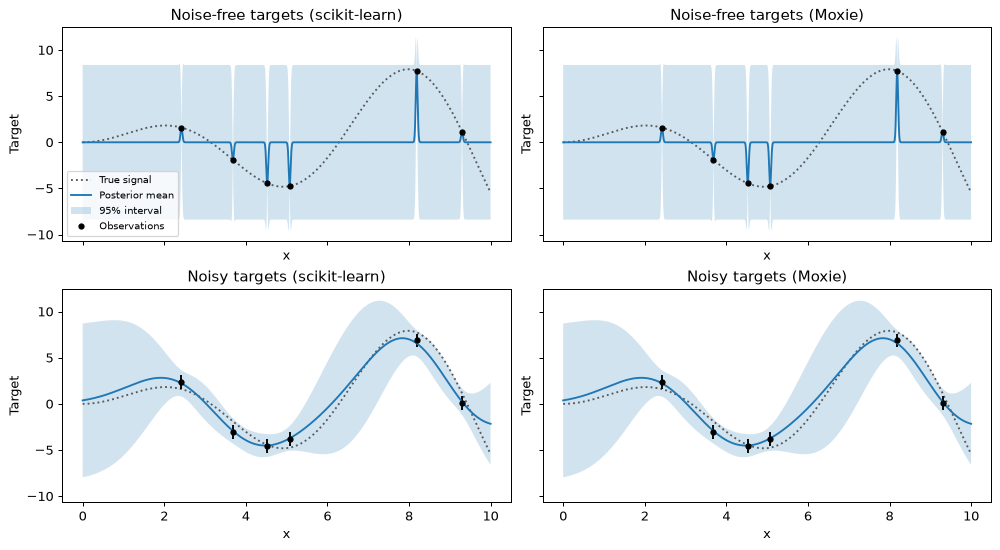

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
clean: mean,PASS,"(1000,)","(1000,)",8.88e-16,3.91e-16,"rtol=1e-09, atol=1e-10",,Cholesky rounding can shift the optimizer endpoint.
clean: std,PASS,"(1000,)","(1000,)",1.33e-15,6.35e-16,"rtol=1e-09, atol=1e-09",,Subtracting nearly equal variances amplifies rounding near training samples.
clean: theta,PASS,"(2,)","(2,)",4.44e-16,1.53e-16,"rtol=1e-09, atol=1e-10",,Cholesky rounding can shift the optimizer endpoint.
clean: lml,PASS,"(1,)","(1,)",0,0,"rtol=1e-09, atol=1e-10",,Cholesky rounding can shift the optimizer endpoint.
noisy: mean,PASS,"(1000,)","(1000,)",4.44e-13,2.95e-11,"rtol=1e-09, atol=1e-10",,Cholesky rounding can shift the optimizer endpoint.
noisy: std,PASS,"(1000,)","(1000,)",1.93e-13,5.26e-14,"rtol=1e-09, atol=1e-09",,Subtracting nearly equal variances amplifies rounding near training samples.
noisy: theta,PASS,"(2,)","(2,)",9.81e-14,5.87e-13,"rtol=1e-09, atol=1e-10",,Cholesky rounding can shift the optimizer endpoint.
noisy: lml,PASS,"(1,)","(1,)",3.55e-15,2.3e-16,"rtol=1e-09, atol=1e-10",,Cholesky rounding can shift the optimizer endpoint.


In [4]:
actual = nb.results["noisy_targets"]
metrics = ("mean", "std", "theta", "lml")
fig, axes = plt.subplots(2, 2, figsize=(11, 6), dpi=90, sharex=True, sharey=True,
                         layout="constrained")
for row, (name, title, targets, errors) in enumerate((
    ("clean", "Noise-free targets", y_clean, None),
    ("noisy", "Noisy targets", y_noisy, noise_std),
)):
    native = {metric: actual[f"{name}_{metric}"] for metric in metrics}
    for ax, (label, result) in zip(axes[row], (("scikit-learn", expected[name]), ("Moxie", native))):
        ax.plot(X[:, 0], signal, linestyle=":", color="0.35", label="True signal")
        ax.errorbar(X_train[:, 0], targets, yerr=errors, fmt="o", markersize=4,
                    color="black", label="Observations")
        ax.plot(X[:, 0], result["mean"], label="Posterior mean")
        half_width = 1.96 * result["std"]
        ax.fill_between(X[:, 0], result["mean"] - half_width, result["mean"] + half_width,
                        alpha=0.2, label="95% interval")
        ax.set(title=f"{title} ({label})", xlabel="x", ylabel="Target")
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.show()

for name in expected:
    for metric in metrics:
        atol = 1e-9 if metric == "std" else 1e-10
        reason = ("Subtracting nearly equal variances amplifies rounding near training samples."
                  if metric == "std" else "Cholesky rounding can shift the optimizer endpoint.")
        nb.compare(
            f"{name}: {metric}", expected[name][metric], actual[f"{name}_{metric}"],
            rtol=1e-9, atol=atol, reason=reason,
        )
nb.report()
nb.assert_parity()